# SUSS quickstart: the main result in a few minutes on a CPU

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/nonberw/suss/blob/main/notebooks/quickstart.ipynb)

One trained in-context predictor (experiment A, seed 0; 0.8M parameters), fresh test episodes, and three checks:

1. **Behaviour.** The transformer tracks the exact Bayes predictor while data are scarce, then flattens at an approximation floor.
2. **Where the information is.** Linear probes read the Bayes estimate from the attention key-value memory (fast weights) far better than from the residual stream, also after projecting the memory down to the residual stream's width.
3. **Causal test.** Replacing *only* the context keys and values of blocks 3-4 with another episode's transfers most of that episode's behaviour; block 1 alone transfers little.

Runs on Colab or locally. Needs `torch`, `numpy`, `matplotlib` (and `mujoco` only for the other experiments).

In [1]:
import os, sys, subprocess, urllib.request, zipfile
if not os.path.exists("suss") and not os.path.exists("../suss"):        # on Colab: fetch the code
    subprocess.run(["git", "clone", "-q", "https://github.com/nonberw/suss.git"], check=True)
    os.chdir("suss")
elif os.path.exists("../suss") and not os.path.exists("suss"):           # running from notebooks/
    os.chdir("..")
sys.path.insert(0, os.getcwd())
ckpt = "runs/a/seed0.pt"
if not os.path.exists(ckpt):                                              # fetch the trained model from the release
    url = "https://github.com/nonberw/suss/releases/download/v0.1.3/suss_quickstart_models.zip"
    urllib.request.urlretrieve(url, "quickstart_models.zip")
    zipfile.ZipFile("quickstart_models.zip").extractall(".")
print("model checkpoint:", ckpt, os.path.getsize(ckpt) // 1000, "kB")

model checkpoint: runs/a/seed0.pt 3216 kB


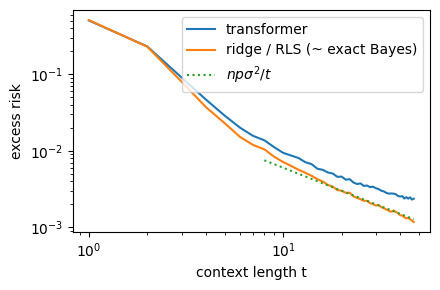

excess risk, transformer / ridge, mean over t >= 4: 1.57


In [2]:
import numpy as np, torch, matplotlib.pyplot as plt
from suss import linear as L
from suss.model import GPT, GPTConfig
from scripts.mech_a3 import fast_weights
from scripts.mech_a4 import run as kv_run
from scripts.mech_a5 import dual_ridge_r2
torch.set_num_threads(4)
ck = torch.load(ckpt, map_location="cpu")
model = GPT(GPTConfig(**ck["cfg"])).eval(); model.load_state_dict(ck["state"])

gen = torch.Generator().manual_seed(2026)
E, T = 4096, 48                                           # as in the paper: 2048 probe-train / 2048 held-out
theta, tok, nxt = L.make_batch(E, T, gen)                 # unknown (A, B) per episode, random inputs
S, C = L.suff_stats(tok, nxt)
th_bayes = L.ridge_theta(S, C)                            # ridge / RLS = Bayes posterior mean under the untruncated prior
mean = L.predict(theta.unsqueeze(1).expand(-1, T, -1, -1), tok)
with torch.no_grad():
    y_tf = model(tok)
ex_tf = ((y_tf - mean) ** 2).sum(-1).mean(0)
ex_b = ((L.predict(th_bayes, tok) - mean) ** 2).sum(-1).mean(0)
t = np.arange(1, T)
plt.figure(figsize=(4.5, 3))
plt.loglog(t, ex_tf[1:], label="transformer"); plt.loglog(t, ex_b[1:], label="ridge / RLS (~ exact Bayes)")
plt.loglog(t[7:], 0.06 / t[7:], ":", label=r"$np\sigma^2/t$")
plt.xlabel("context length t"); plt.ylabel("excess risk"); plt.legend(); plt.tight_layout(); plt.show()
print("excess risk, transformer / ridge, mean over t >= 4: %.2f" % float((ex_tf[4:] / ex_b[4:]).mean()))

In [3]:
half = E // 2
y = th_bayes[:, -1].reshape(E, -1).double()               # the estimate at t = 47 (6 numbers), the probe target
with torch.no_grad():
    _, res = model(tok, return_resid=True)
print("held-out R^2 of a linear (ridge) probe for the estimate; every column but the last is 128-d")
print("block | resid. query | resid. mean-pooled | K,V random 128-d | K,V full 4224-d")
for l in range(4):
    F = fast_weights(model, tok, l, T - 1).float()         # per-head Cov(v, k) of block l: the key-value memory
    P = torch.randn(F.shape[1], 128, generator=torch.Generator().manual_seed(l)) / 128 ** 0.5
    feats = [res[l + 1][:, -1], res[l + 1].mean(1), F @ P, F]
    r2 = [dual_ridge_r2(X[:half], y[:half], X[half:], y[half:])[0] for X in feats]
    print(f"  {l + 1}   |    " + "    |    ".join(f"{v:5.2f}" for v in r2))

held-out R^2 of a linear (ridge) probe for the estimate; every column but the last is 128-d
block | resid. query | resid. mean-pooled | K,V random 128-d | K,V full 4224-d


  1   |     0.02    |     0.30    |    -0.00    |    -0.01


  2   |     0.11    |     0.56    |     0.37    |     0.43


  3   |     0.17    |     0.59    |     0.74    |     0.81


  4   |     0.26    |     0.58    |     0.86    |     0.92


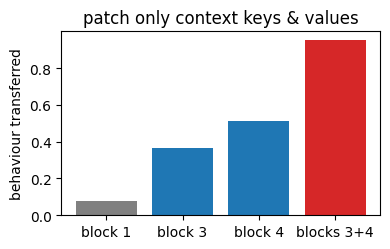

{'block 1': 0.08, 'block 3': 0.37, 'block 4': 0.51, 'blocks 3+4': 0.95}


In [4]:
idxB = torch.arange(half, E); idxA = torch.roll(idxB, -1)
tokB = tok[idxB]
tokA2 = torch.cat([tok[idxA, :-1], tok[idxB, -1:]], 1)    # episode A's context with episode B's query
with torch.no_grad():
    yB, _ = kv_run(model, tokB); yA, kvA = kv_run(model, tokA2)
    yB, yA = yB[:, -1], yA[:, -1]; d = yA - yB; den = (d ** 2).sum(-1)
    tau = lambda yp: float((((yp[:, -1] - yB) * d).sum(-1) / den).mean())
    out = {name: tau(kv_run(model, tokB, kvA, blocks, "kv")[0]) for name, blocks in
           [("block 1", (0,)), ("block 3", (2,)), ("block 4", (3,)), ("blocks 3+4", (2, 3))]}
plt.figure(figsize=(4, 2.6)); plt.bar(list(out), list(out.values()), color=["grey", "C0", "C0", "C3"])
plt.ylabel("behaviour transferred"); plt.title("patch only context keys & values"); plt.tight_layout(); plt.show()
print({k: round(v, 2) for k, v in out.items()})

**What the paper reports** (fixed reference episodes, hierarchical bootstrap): excess-risk ratio 1.59 (1.58 +- 0.03 over 10 seeds); probe R^2 for the estimate 0.90-0.91 from the key-value memory and 0.84-0.86 after a random projection to 128 dimensions, against at most 0.58-0.61 from the residual stream however it is read; patching only the keys and values of blocks 3-4 transfers 0.91-0.94 of the other episode's behaviour (0.93 +- 0.01 over 10 seeds), block 1 alone 0.07-0.16. The episodes above are fresh, so expect numbers close to these, not identical.

Everything else (MuJoCo systems, the controller, all seeds and controls): `bash scripts/run_all.sh`. Paper: [`paper/main.pdf`](../paper/main.pdf). All 51 trained checkpoints: `suss_models.zip` in the [v0.1.3 release](https://github.com/nonberw/suss/releases/tag/v0.1.3).